# Cold battery check: does temperature change how fast the battery voltage drops?

SmartSolo nodes run on an internal lithium-ion pack (about 8.3 V when full, two cells in series). The data sheet gives an operating range of −40 to +70 °C and 30 days of recording at 2 ms (24 h/day), specified at 25 °C ([SmartSolo IGU-16HR 3C data sheet](https://smartsolo.com/sc/IGU-16HR%203C.pdf)). Lithium-ion cells lose available capacity and power in the cold because their internal resistance rises, so the voltage under load falls further and the cut-off voltage is reached sooner ([review in *Heliyon*, 2025](https://pmc.ncbi.nlm.nih.gov/articles/PMC12022756/); [Atlantis Press study](https://www.atlantis-press.com/article/25887654.pdf)). For Antarctic deployments the practical question is whether this matters at the temperatures the nodes actually see.

This notebook reads **every `DigiSolo.LOG` under a folder** (by content, any file name), pairs the battery voltage (`[Battery]` records, every 30 min) with the logged temperature (`[Temperature]`, every 10 min), and tests three things:

1. **Overall discharge rate** of each installation against its mean temperature.
2. **Voltage gradient against temperature**: the 6-hour voltage gradient dV/dt against temperature, controlling for the state of charge, which also changes the gradient.
3. **Short-term response**: whether the detrended voltage follows the daily temperature cycle, and with what delay.

Set `DATA_ROOT` to a harvest to run it on more nodes. Installations shorter than `MIN_DAYS` are listed but not used for the gradient analysis.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
sys.path.insert(0, "../../lib")
import smartsolo_locate as loc, smartsolo_log as sl, smartsolo_node as sn

DATA_ROOT = Path("../../data")     # every DigiSolo.LOG below this folder is read
MIN_DAYS = 2.0                     # installations shorter than this are only listed
STEP = "30min"                     # common time step (the Battery record interval)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})

## Read all logs
One installation is one power-up of one node (`serial`, `session`). Voltage and temperature are interpolated onto a common 30-min grid.

In [3]:
logs = loc.find_logs(DATA_ROOT)
logs = [p for p in logs if "simulation" not in p.parts]       # skip synthetic huddle-test nodes, if present
df = sl.read_logs(logs)
print(f"{len(logs)} logs, {df.serial.nunique()} nodes")

def installation_series(g, step=STEP):
    v, t = g.voltage.dropna(), g.temperature.dropna()
    if len(v) < 4 or len(t) < 4:
        return None
    idx = pd.date_range(v.index.min().ceil(step), v.index.max().floor(step), freq=step)
    V = v.reindex(v.index.union(idx)).interpolate("time").reindex(idx)
    T = t.reindex(t.index.union(idx)).interpolate("time", limit_area="inside").reindex(idx)
    return pd.DataFrame(dict(V=V, T=T)).dropna()

inst, rows = {}, []
for (serial, session), g in df.groupby(["serial", "session"]):
    d = installation_series(g)
    if d is None or len(d) < 4:
        continue
    days = (d.index[-1] - d.index[0]).total_seconds() / 86400
    rate = np.polyfit((d.index - d.index[0]).total_seconds() / 86400, d.V, 1)[0]
    rows.append(dict(serial=serial, session=int(session), start=d.index[0], days=round(days, 2),
                     V_start=d.V.iloc[0], V_end=d.V.iloc[-1], rate_mV_per_day=1000 * rate,
                     T_min=d["T"].min(), T_mean=d["T"].mean(), T_max=d["T"].max(), used=days >= MIN_DAYS))
    inst[(serial, int(session))] = d
summary = pd.DataFrame(rows).round(3)
summary

13 logs, 13 nodes


,serial,session,start,days,V_start,V_end,rate_mV_per_day,T_min,T_mean,T_max,used
0,453004362,3,2023-04-07 00:30:00+00:00,0.12,8.107,8.097,-84.693,17.000,17.733,18.590,False
1,453009194,3,2023-04-07 00:30:00+00:00,0.12,8.179,8.168,-91.412,17.000,17.779,18.670,False
2,453010029,5,2023-04-07 00:30:00+00:00,0.12,8.252,8.245,-47.507,16.875,17.673,18.539,False
3,453010047,3,2023-04-07 00:30:00+00:00,0.12,7.491,7.488,-29.410,17.500,18.226,19.011,False
4,453010077,3,2023-04-07 00:30:00+00:00,0.12,8.266,8.251,-119.882,16.875,17.661,18.622,False
5,453010167,4,2023-04-07 00:30:00+00:00,0.12,7.682,7.673,-80.007,17.312,18.039,18.750,False
6,453021081,7,2023-12-29 08:30:00+00:00,31.79,8.340,6.010,-60.586,-22.688,-13.039,6.008,True
7,453021267,4,2024-12-25 15:00:00+00:00,13.73,8.249,7.634,-44.551,-14.000,-4.825,7.669,True
8,453021679,5,2023-12-29 05:30:00+00:00,32.31,8.267,6.034,-59.371,-25.699,-13.124,-1.844,True
9,453021767,6,2023-12-28 02:00:00+00:00,1.23,8.273,8.207,-56.924,-18.827,-4.249,6.955,False


## Voltage and temperature against time
The script thresholds of these nodes are 6.5 V (low battery) and 6.0 V (critical). Note that the voltage drop is not linear in time: lithium-ion discharge curves are flat in the middle and steepen towards both ends, so the state of charge changes the gradient by itself.

In [14]:
d.index[0]

Timestamp('2024-12-25 16:00:00+0000', tz='UTC')

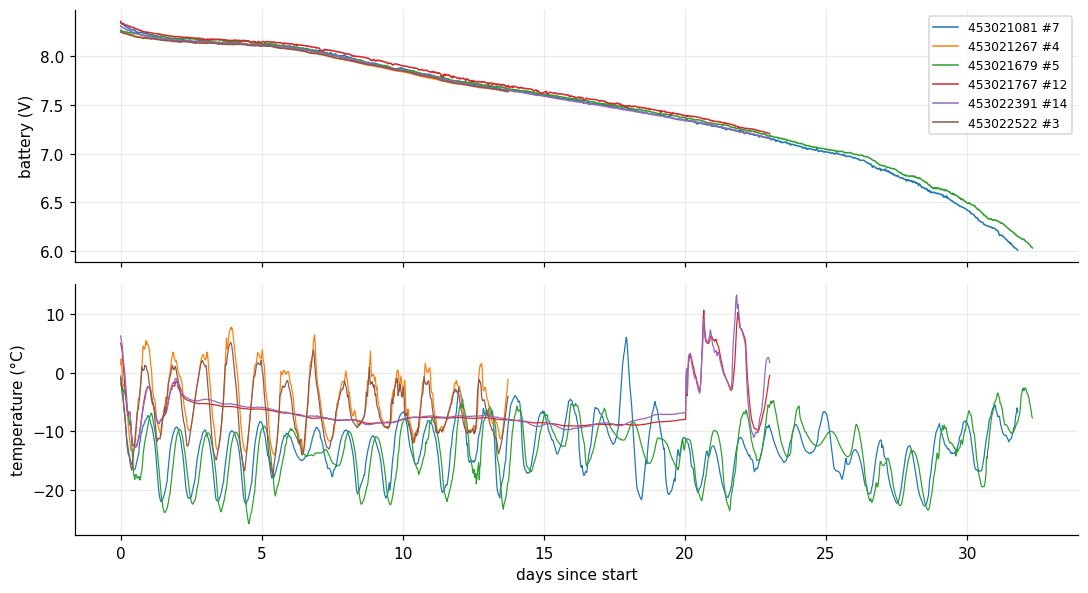

In [15]:
use = [k for k, d in inst.items() if (d.index[-1] - d.index[0]).total_seconds() / 86400 >= MIN_DAYS]
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

for k in use:
    d = inst[k]
    days_elapsed = (d.index - d.index[0]).total_seconds() / 86400.0
    axes[0].plot(days_elapsed, d.V, lw=1, label=f"{k[0]} #{k[1]}")
    axes[1].plot(days_elapsed, d["T"], lw=0.8)

axes[0].set_ylabel("battery (V)")
axes[1].set_ylabel("temperature (°C)")
axes[1].set_xlabel("days since start")

axes[0].legend(fontsize=8)


fig.tight_layout()


## 1. Overall discharge rate against mean temperature
One point per installation. With few long installations this is only indicative, and it mixes nodes with different batteries, sample rates and duty cycles.

[Text(0.5, 0, 'mean temperature (°C)'),
 Text(0, 0.5, 'mean voltage gradient (mV/day)'),
 Text(0.5, 1.0, 'o: ≥ MIN_DAYS, x: short installations')]

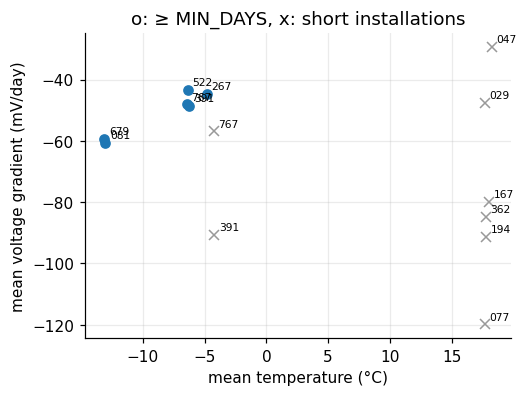

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.6))
for r in summary.itertuples():
    ax.plot(r.T_mean, r.rate_mV_per_day, "o" if r.used else "x", ms=6, color="C0" if r.used else "0.6")
    ax.annotate(f"{r.serial[-3:]}", (r.T_mean, r.rate_mV_per_day), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="mean temperature (°C)", ylabel="mean voltage gradient (mV/day)",
       title="o: ≥ MIN_DAYS, x: short installations")

## 2. Voltage gradient against temperature
For each long installation the voltage gradient dV/dt is taken over 6-hour windows and modelled as

dV/dt = a + c·T + e·dT/dt + b₁·(V − V̄) + b₂·(V − V̄)²

The temperature term c is the effect of interest. The dT/dt term takes up the immediate, reversible voltage response to warming or cooling. The polynomial in voltage stands for the state of charge, so that the steepening discharge curve is not mistaken for a temperature effect. Uncertainties come from a block bootstrap that resamples whole days.

In [6]:
def gradient_table(d, window="6h"):
    h = d.resample(window).mean()
    hrs = pd.Timedelta(window).total_seconds() / 86400
    out = pd.DataFrame(dict(dVdt=h.V.diff() / hrs * 1000, T=h["T"], dTdt=h["T"].diff() / hrs, V=h.V)).dropna()
    out["day"] = out.index.floor("1D")
    return out

def fit(g):
    v = g.V - g.V.mean()
    X = np.column_stack([np.ones(len(g)), g["T"], g.dTdt, v, v ** 2])
    b, *_ = np.linalg.lstsq(X, g.dVdt, rcond=None)
    res = g.dVdt - X @ b
    return b, 1 - res.var() / g.dVdt.var()

def bootstrap(g, n=500, seed=0):
    rng = np.random.default_rng(seed); days = g.day.unique(); out = []
    for _ in range(n):
        pick = rng.choice(days, len(days), replace=True)
        out.append(fit(pd.concat([g[g.day == x] for x in pick]))[0])
    return np.array(out)

res = []
for k in use:
    g = gradient_table(inst[k])
    b, r2 = fit(g); bs = bootstrap(g)
    lo, hi = np.percentile(bs[:, 1], [2.5, 97.5])
    mean_rate = g.dVdt.mean()
    res.append(dict(serial=k[0], session=k[1], n_windows=len(g), mean_gradient_mV_day=mean_rate,
                    c_mV_day_per_C=b[1], c_lo=lo, c_hi=hi, e_mV_day_per_C_day=b[2], R2=r2,
                    change_per_10C_percent=100 * 10 * b[1] / abs(mean_rate)))
grad = pd.DataFrame(res).round(3)
grad

,serial,session,n_windows,mean_gradient_mV_day,c_mV_day_per_C,c_lo,c_hi,e_mV_day_per_C_day,R2,change_per_10C_percent
0,453021081,7,127,-72.447,1.672,0.706,3.076,0.446,0.752,23.077
1,453021267,4,55,-44.080,2.869,2.177,3.564,-0.367,0.504,65.097
2,453021679,5,130,-68.552,3.102,1.703,4.882,-0.495,0.737,45.245
3,453021767,12,92,-49.080,0.570,-1.454,6.650,-0.080,0.048,11.605
4,453022391,14,92,-49.399,0.837,-1.152,5.369,0.103,0.094,16.936
5,453022522,3,55,-43.881,3.372,2.309,4.681,-0.588,0.457,76.838


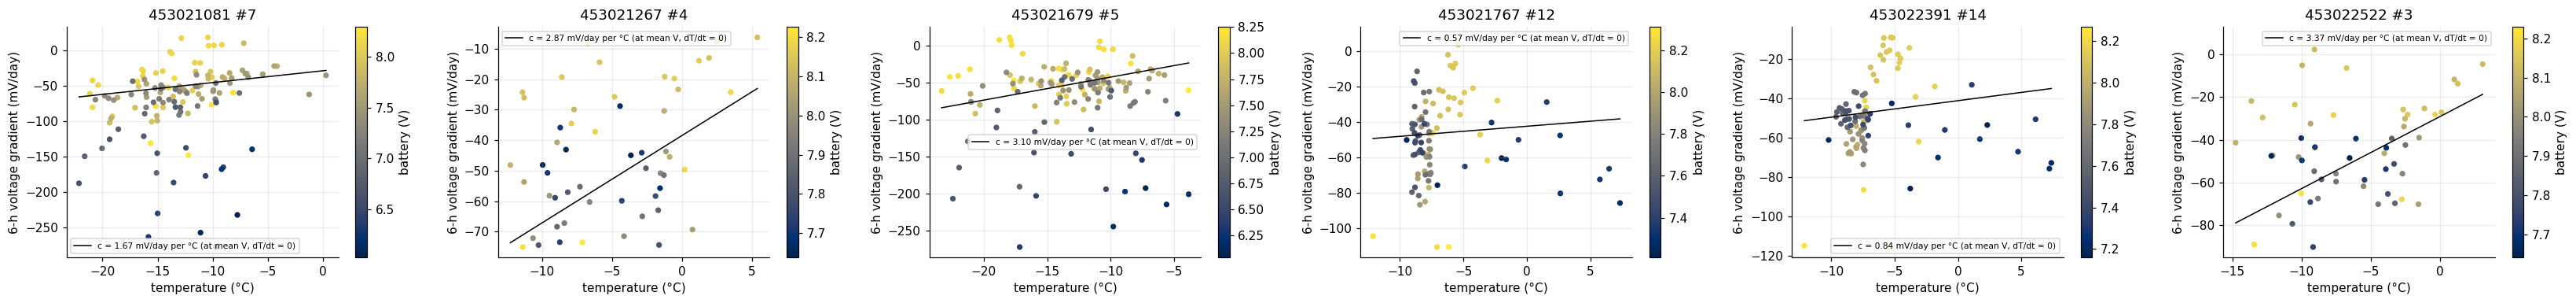

In [7]:
fig, axes = plt.subplots(1, len(use), figsize=(5 * len(use), 3.6), squeeze=False)
for ax, k in zip(axes[0], use):
    g = gradient_table(inst[k])
    sc = ax.scatter(g["T"], g.dVdt, c=g.V, cmap="cividis", s=14)
    b, _ = fit(g)
    x = np.linspace(g["T"].min(), g["T"].max(), 10)
    ax.plot(x, b[0] + b[1] * x, "k-", lw=1, label=f"c = {b[1]:.2f} mV/day per °C (at mean V, dT/dt = 0)")
    ax.set(xlabel="temperature (°C)", ylabel="6-h voltage gradient (mV/day)", title=f"{k[0]} #{k[1]}")
    ax.legend(fontsize=7); fig.colorbar(sc, ax=ax, label="battery (V)")
fig.tight_layout()

### 2b. Whole-day windows
Reversible effects largely cancel over a full day. Repeating the fit with 24-hour windows (stepped by 6 h, so neighbouring windows overlap) shows whether the temperature effect survives once the daily cycle is averaged out. The daily mean temperature varies much less than the 6-hourly one, so this test is weaker.

In [8]:
daily = []
for k in use:
    d = inst[k]; rows = []
    for t0 in pd.date_range(d.index[0], d.index[-1] - pd.Timedelta("24h"), freq="6h"):
        w = d[(d.index >= t0) & (d.index < t0 + pd.Timedelta("24h"))]
        x = (w.index - w.index[0]).total_seconds() / 86400
        rows.append(dict(g=1000 * np.polyfit(x, w.V, 1)[0], T=w["T"].mean(), V=w.V.mean()))
    r = pd.DataFrame(rows); v = r.V - r.V.mean()
    X = np.column_stack([np.ones(len(r)), r["T"], v, v ** 2]); b, *_ = np.linalg.lstsq(X, r.g, rcond=None)
    X0 = np.column_stack([np.ones(len(r)), v, v ** 2]); b0, *_ = np.linalg.lstsq(X0, r.g, rcond=None)
    res0 = r.g - X0 @ b0
    daily.append(dict(serial=k[0], session=k[1], windows=len(r), T_range=f"{r['T'].min():.1f} to {r['T'].max():.1f}",
                      c_daily_mV_day_per_C=b[1], corr_T_vs_SOC_residual=np.corrcoef(res0, r["T"])[0, 1]))
pd.DataFrame(daily).round(3)

,serial,session,windows,T_range,c_daily_mV_day_per_C,corr_T_vs_SOC_residual
0,453021081,7,124,-17.7 to -5.9,-0.905,-0.110
1,453021267,4,51,-6.7 to -2.5,8.211,0.257
2,453021679,5,126,-18.3 to -7.0,0.597,0.074
3,453021767,12,89,-9.0 to 3.6,-0.115,-0.009
4,453022391,14,89,-9.5 to 3.3,0.296,0.023
5,453022522,3,51,-8.0 to -4.6,5.363,0.237


## 3. Short-term response: does the voltage follow the daily temperature cycle?
Both series are detrended with a 24-h running mean. The cross-correlation then shows how strongly the remaining voltage follows the temperature, and at what delay. A positive delay means the voltage follows the temperature.

Interpret delays near 6 h with care. For a daily cycle, a 6-h delay is the same as following the rate of change of temperature rather than the temperature itself, which is what a temperature-dependent gradient (section 2) produces.

,serial,session,best_delay_h,cc,cc_at_zero,slope_mV_per_C,V_resid_std_mV,T_resid_std_C
0,453021081,7,3.0,0.497,0.340,0.816,6.349,3.862
1,453021267,4,6.0,0.579,-0.095,0.288,2.525,4.953
2,453021679,5,6.5,0.612,-0.140,0.896,5.492,3.755
3,453021767,12,-12.0,0.197,-0.170,0.613,5.074,1.736
4,453022391,14,10.0,0.300,-0.154,0.386,2.330,1.894
5,453022522,3,7.5,0.612,-0.344,0.370,2.924,4.664


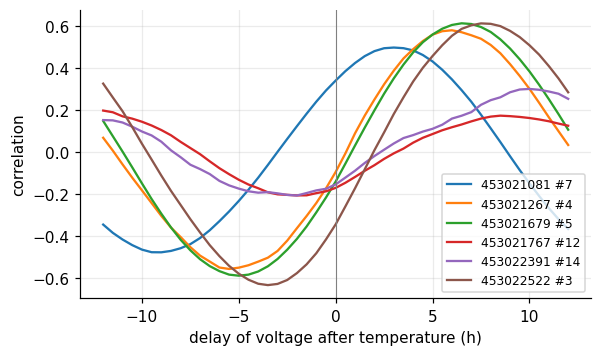

In [9]:
def detrended(d, hours=24):
    n = int(pd.Timedelta(f"{hours}h") / pd.Timedelta(STEP))
    return (d - d.rolling(n, center=True, min_periods=int(0.8 * n)).mean()).dropna()

fig, ax = plt.subplots(figsize=(6, 3.4)); lagtab = []
lags = np.arange(-24, 25)
for k in use:
    r = detrended(inst[k])
    cc = [r.V.corr(r["T"].shift(l)) for l in lags]
    L = lags[int(np.nanargmax(cc))]
    rr = pd.concat([r.V, r["T"].shift(L)], axis=1).dropna()
    lagtab.append(dict(serial=k[0], session=k[1], best_delay_h=L / 2, cc=np.nanmax(cc), cc_at_zero=cc[24],
                       slope_mV_per_C=1000 * np.polyfit(rr["T"], rr.V, 1)[0],
                       V_resid_std_mV=1000 * r.V.std(), T_resid_std_C=r["T"].std()))
    ax.plot(lags / 2, cc, label=f"{k[0]} #{k[1]}")
ax.axvline(0, color="0.5", lw=0.7); ax.set(xlabel="delay of voltage after temperature (h)", ylabel="correlation")
ax.legend(fontsize=8)
pd.DataFrame(lagtab).round(3)

## 4. Two nodes side by side
Where two nodes recorded at the same time, they share the weather but differ slightly in temperature (sun, burial, snow cover). If cold increases the discharge rate, the colder node should lose voltage faster. Shown: the voltage difference (A − B) and the temperature difference (A − B).

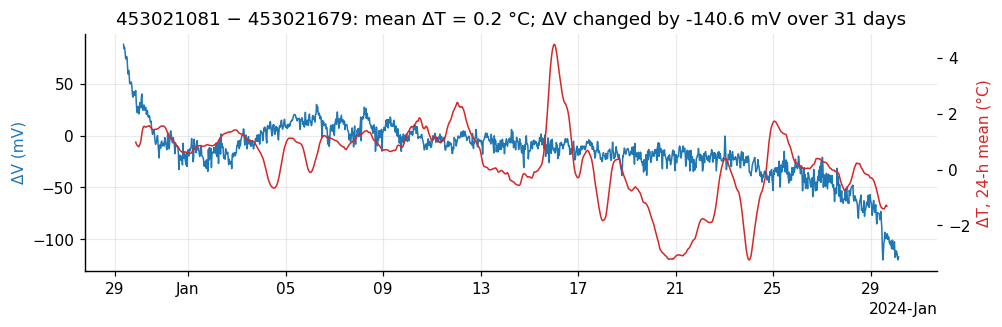

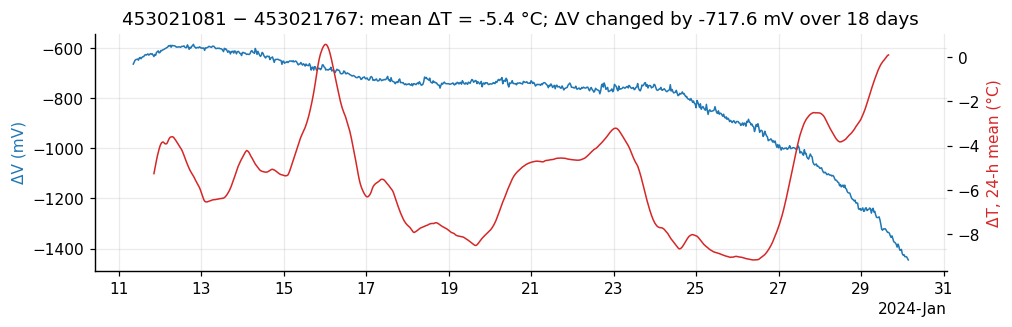

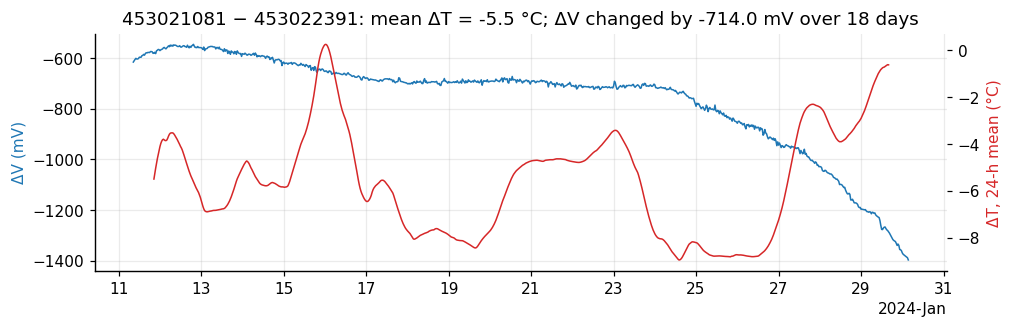

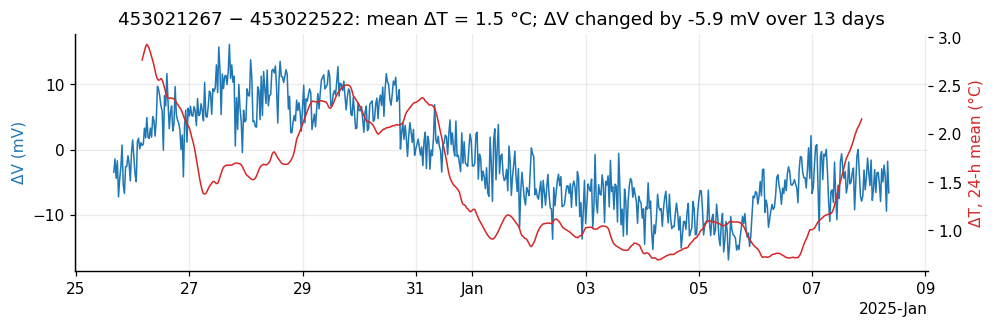

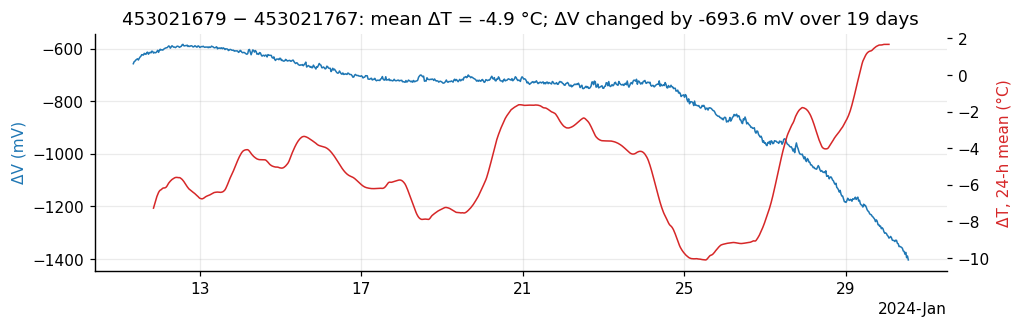

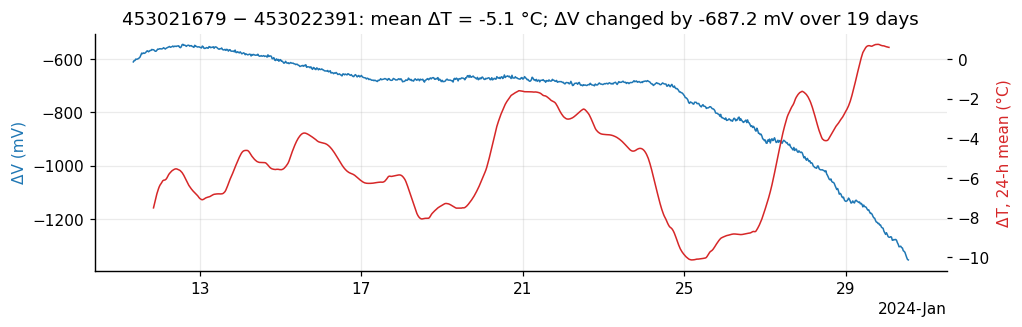

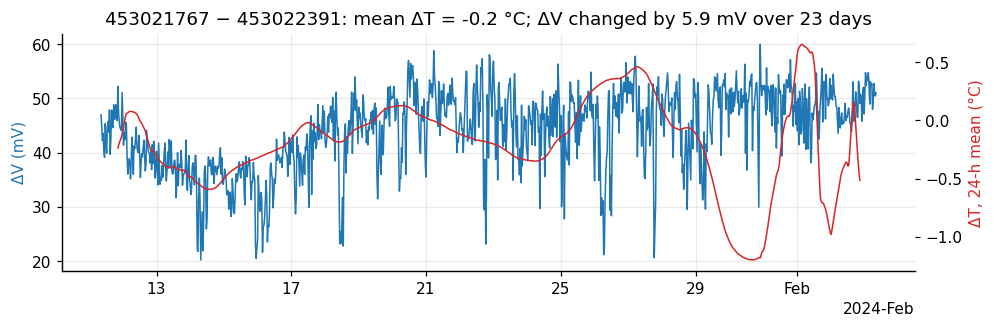

In [10]:
pairs = []
for i, a in enumerate(use):
    for b in use[i + 1:]:
        j = inst[a].join(inst[b], lsuffix="_a", rsuffix="_b", how="inner")
        if len(j) > 96:
            pairs.append((a, b, j))
for a, b, j in pairs:
    dV, dT = 1000 * (j.V_a - j.V_b), j.T_a - j.T_b
    fig, ax = plt.subplots(figsize=(10, 2.8)); ax2 = ax.twinx()
    ax.plot(j.index, dV, color="C0", lw=1); ax2.plot(j.index, dT.rolling(48, center=True).mean(), color="C3", lw=1)
    ax.set_ylabel("ΔV (mV)", color="C0"); ax2.set_ylabel("ΔT, 24-h mean (°C)", color="C3")
    ax.set_title(f"{a[0]} − {b[0]}: mean ΔT = {dT.mean():.1f} °C; ΔV changed by "
                 f"{dV.iloc[-48:].mean() - dV.iloc[:48].mean():.1f} mV over {(j.index[-1] - j.index[0]).days} days")
    ax2.grid(False)
    l_ = mdates.AutoDateLocator(); ax.xaxis.set_major_locator(l_); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(l_))
if not pairs:
    print("no overlapping long installations")

## 5. How long would the battery last?
A rough extrapolation of the last three days to the 6.5 V low-battery threshold. The second column is a **worst case**: it treats the 6-hour temperature coefficient as a permanent effect, at a site 10 °C colder. This is only indicative, because the discharge curve steepens towards the end.

In [11]:
rows = []
for k in use:
    d = inst[k]; last = d[d.index > d.index[-1] - pd.Timedelta("3D")]
    slope = np.polyfit((last.index - last.index[0]).total_seconds() / 86400, last.V, 1)[0] * 1000   # mV/day
    c = grad.set_index(["serial", "session"]).loc[k, "c_mV_day_per_C"]
    left = 1000 * (d.V.iloc[-1] - 6.5)
    rows.append(dict(serial=k[0], session=k[1], V_now=d.V.iloc[-1], recent_mV_per_day=slope,
                     days_to_6p5V=left / -slope if slope < 0 else np.inf,
                     days_to_6p5V_10C_colder=left / -(slope - 10 * c) if slope - 10 * c < 0 else np.inf,
                     days_recorded=(d.index[-1] - d.index[0]).total_seconds() / 86400))
pd.DataFrame(rows).round(2)

,serial,session,V_now,recent_mV_per_day,days_to_6p5V,days_to_6p5V_10C_colder,days_recorded
0,453021081,7,6.01,-201.87,-2.43,-2.24,31.79
1,453021267,4,7.63,-49.17,23.07,14.57,13.73
2,453021679,5,6.03,-189.29,-2.46,-2.12,32.31
3,453021767,12,7.21,-63.31,11.14,10.22,23.00
4,453022391,14,7.15,-63.85,10.24,9.06,23.00
5,453022522,3,7.64,-51.84,22.01,13.33,13.73


## What the repository data show

The two Dronning Maud Land nodes are the only long installations here: two weeks at −17 to +8 °C, recording at 1000 sps. The six break-test logs cover 3 h at 17–20 °C; they are listed but not analysed.

- **Overall discharge.** Both nodes lost 0.61–0.62 V in 13.7 days (about −44 mV/day), at mean temperatures of −4.8 and −6.4 °C. The gradient changes more with the state of charge than with anything else: it steepens after about six days, as expected for a lithium-ion discharge curve.
- **6-hour gradient against temperature.** The coefficient c is +2.9 and +3.4 mV/day per °C (bootstrap 95 % range 2.2–4.7). In colder 6-hour windows the voltage falls faster. Taken at face value, a site 10 °C colder would see a 65–77 % steeper decline.
- **Whole-day windows do not settle it.** With 24-hour windows (2b), c comes out at 5–8 mV/day per °C. However, the daily means span only 4 °C, and temperature explains about 6 % of the variance left after the state of charge. The days were also colder in the second week, just when the discharge curve steepened, so this estimate is confounded with the state of charge.
- **The effect is largely reversible.** The detrended voltage follows the temperature with a delay of 6–7.5 h (section 3). The node comparison is the cleanest test, because both nodes share time and state of charge. 453022522 was 1.5 °C colder on average, yet it lost about 6 mV *less* than 453021267 over the deployment. A permanent effect of 3 mV/day per °C would have made it lose about 60 mV *more*.
- **Interpretation.** The logged voltage most likely follows the battery's own temperature, which lags the logged case temperature by hours. Cold raises the internal resistance and lowers the terminal voltage; warming restores it. Any lasting loss of capacity between −17 and +8 °C is below what two weeks and two batteries can resolve. Battery-to-battery differences of a few mV set that limit.
- **Practical consequence.** Temperature does not limit a two-week deployment at these temperatures. Expect cold nights to lower the voltage temporarily, though. Near the end of a deployment this can bring the 6.5 V low-battery threshold forward by hours to days. The worst case in section 5 (−10 °C, permanent effect) gives 13–15 days to 6.5 V instead of 22–23.

Colder sites (−30 °C and below) and longer deployments need more data. Add logs under `DATA_ROOT` and re-run.